# Multi-illumination intrinsic fields

## 1. Problem

Separate stable material reflectance from changing illumination in real photographs. A dark patch is ambiguous: it may be dark paint or a shadow. We reconstruct **both** relative reflectance and the shading under the reference light, on the complete native object foreground.

This review runs the cleaned reconstruction, evaluates two independently measured relative references, and computes every fresh method shown below. The selected benchmark method is parameter-free Weiss, chosen before inspecting reconstruction quality. A stronger optional comparison does not replace it. The primary input is grayscale; the color comparison receives an explicitly different RGB observation.

The paper's unavailable trained methods and its whole-dataset aggregate scores are not fresh experiments here. We retain the distributed baseline family and report this one full bound acquisition.

In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,time,json,subprocess,importlib.util
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'data/raw_data.npz').exists():ROOT=ROOT.parent
assert (ROOT/'data/raw_data.npz').is_file()
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations
from src.physics_model import gradients,normal_equations
from src.solvers import estimate,median_targets
from src.main import run
from src.generate_data import perturb_observations
from src.visualization import image_grid,field_metrics,scientific_style
scientific_style()
export=Path(os.environ.get('IMAGING_REVIEW_EXPORT',str(ROOT.parents[2]/'imaging-101-maintainer/review_exports'/ROOT.name)))
export.mkdir(parents=True,exist_ok=True);original_show=plt.show;figure_counter=0
def review_show(*args,**kwargs):
    global figure_counter
    for number in plt.get_fignums():
        figure_counter+=1;figure=plt.figure(number)
        for suffix in ('png','svg','pdf'):figure.savefig(export/f'figure_{figure_counter:02d}.{suffix}',bbox_inches='tight')
    return original_show(*args,**kwargs)
plt.show=review_show
started=time.perf_counter();x=load_observations(ROOT/'data/raw_data.npz');m=x['mask'];REF=ROOT/'notebooks/reference_outputs'
with np.load(ROOT/'evaluation/ground_truth.npz',allow_pickle=False) as z:truth={k:z[k][0] for k in ('shading','reflectance')}
with np.load(REF/'upstream_default.npz',allow_pickle=False) as z:upstream={k:z[k][0] for k in z.files}
with np.load(REF/'colour_context_measurement.npz',allow_pickle=False) as z:rgb=z['reference_rgb']
print('Full bound image',x['image'].shape,'all illumination images',x['multiple'].shape[-1],'foreground pixels',int(m.sum()))
print('Intensity range in original uint16 PNG/255 units',float(x['multiple'].min()),float(x['multiple'].max()))

Full bound image (600, 534) all illumination images 10 foreground pixels 70430
Intensity range in original uint16 PNG/255 units 0.0 254.99607843137255


## 2. Data

These are ten real author-acquired illuminations of the same painted dinosaur. The native grid is600×534; no crop, resize, target-based support selection, or omitted foreground pixel is used. The mask is supplied independently. The uint16 photographs are divided by255 exactly as in the original loader; values are **not** assumed to lie in[0,1].

Independent relative reflectance comes from a separately prepared/captured reference experiment; shading has its own independent measurement and gain. These measurements are used only for evaluation, never to construct an acquisition calibration or initialize the inverse. The RGB reference shown later belongs only to the color-method context. Camera exposure, light directions, and calibrated absolute albedo are unavailable.

findfont: Failed to find font weight semibold, now using 700.


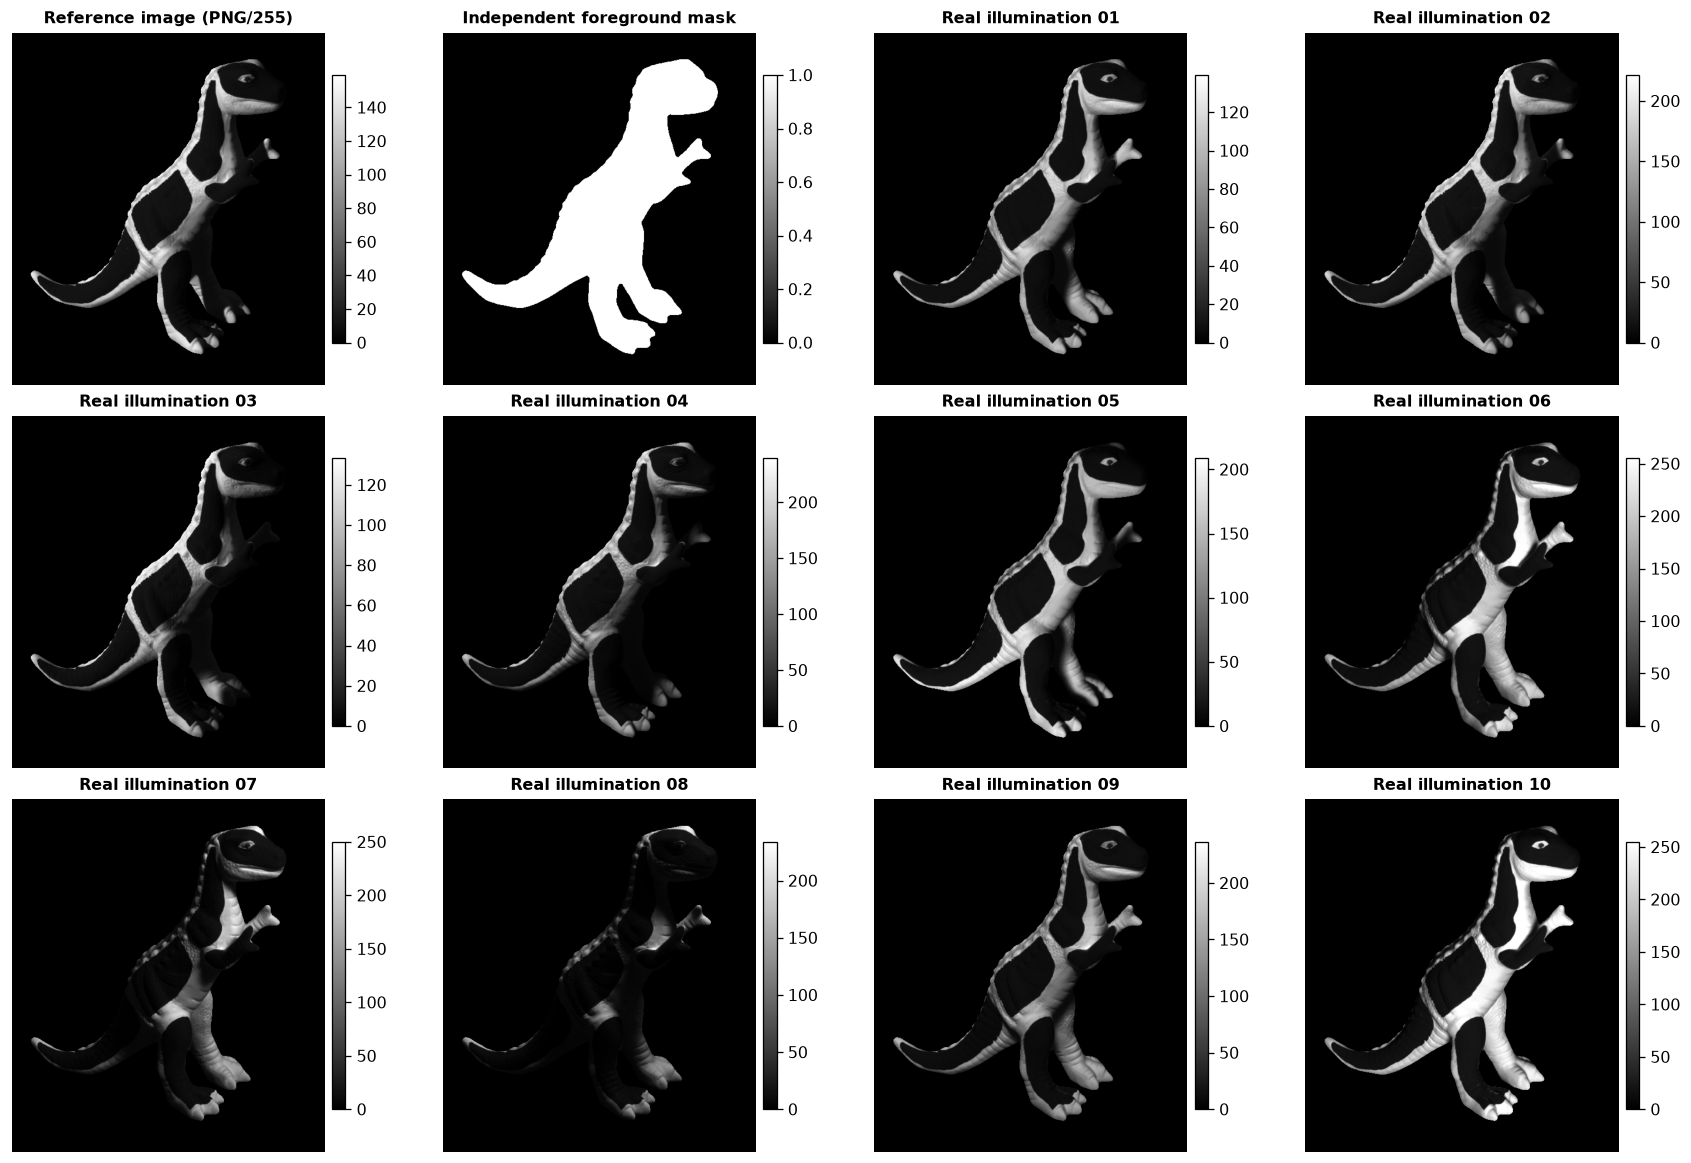

In [2]:
image_grid([x['image'],m.astype(float)]+[x['multiple'][...,k] for k in range(10)],['Reference image (PNG/255)','Independent foreground mask']+[f'Real illumination {k+1:02d}' for k in range(10)],columns=4,figsize=(15,10));plt.show()

## 3. Physics

For pixel p and light k, the diffuse approximation is

$$I_k(p)=R(p)S_k(p)+e_k(p).$$

R is relative material reflectance, S is light-dependent shading, and e includes noise and model mismatch. Logarithms make the two factors additive. Illumination changes should cancel in a median of log-image gradients, while consistent material boundaries remain. Shadows and specularities can violate this assumption.

The method estimates a relative field: multiplying R by a positive constant and dividing S by it leaves the image unchanged. We fix mean(log R)=0 over the foreground. The reference shading follows from the unmodified observed reference intensity, so its product with R must recover that image. Matching this product alone is insufficient: both trivial all-shading and all-reflectance decompositions do so.

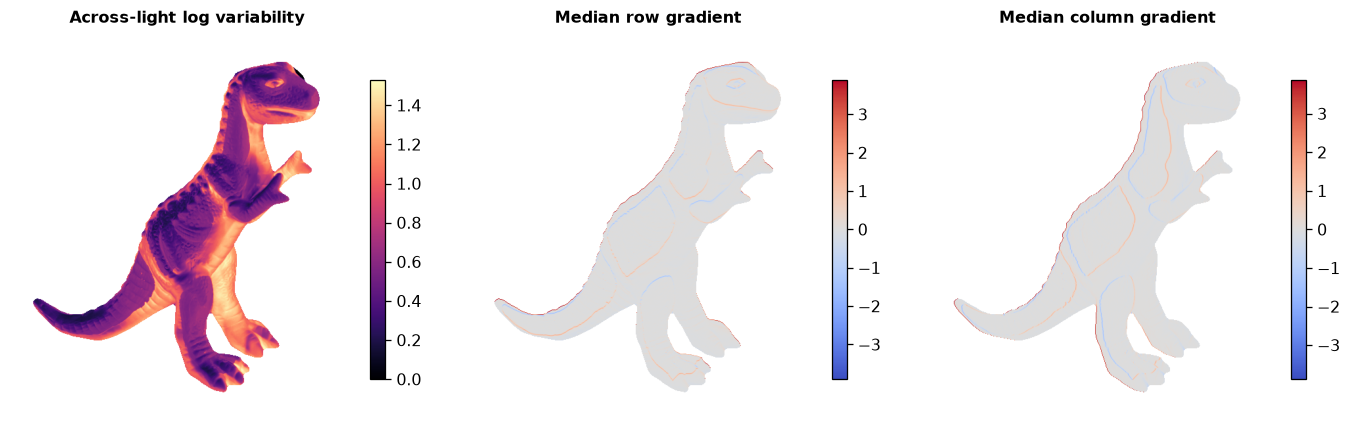

Explicit local normal matrix (70430, 70430) nonzeros 349448 constant-null residual 0.0


In [3]:
ty,tx=median_targets(x['multiple']);A,b,numbers=normal_equations(ty,tx,m)
variability=np.std(np.log(np.maximum(x['multiple'],3.)),axis=-1)
image_grid([np.where(m,variability,np.nan),np.where(m,ty,np.nan),np.where(m,tx,np.nan)],['Across-light log variability','Median row gradient','Median column gradient'],cmap=['magma','coolwarm','coolwarm']);plt.show()
print('Explicit local normal matrix',A.shape,'nonzeros',A.nnz,'constant-null residual',float(np.max(abs(A@np.ones(A.shape[0])))))

## 4. Method

The published primary baseline floors illumination intensity at3 in PNG/255 units before taking logarithms. For each neighboring row/column pair it takes the median log gradient across all ten lights. Let D be the backward-difference incidence matrix over edges wholly inside the mask, t the median target gradient, and u=log R. Solve

$$\min_u\;\tfrac12\lVert Du-t\rVert_2^2,\qquad \mathrm{mean}(u)=0.$$

The local code explicitly assembles A=DᵀD and b=Dᵀt. Conjugate gradients with Jacobi preconditioning solves the constant-projector gauge-fixed system to relative residual1e-11. The original uses generic AMG at1e-5; its separately run1e-10 diagnostic establishes the integration-precision envelope. This backend distinction is recorded, rather than claiming bitwise default-AMG parity.

The optional robust method uses20 explicit IRLS updates with weights1/(2 max(|residual|,1e-4)). Grayscale Retinex, color Retinex and Weiss–Retinex use fixed threshold0.1 without hidden-reference tuning. All fresh arrays below are computed through local src modules.

In [4]:
primary_started=time.perf_counter();fresh=run(ROOT);primary_seconds=time.perf_counter()-primary_started
command=[sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')]
judge=subprocess.run(command,cwd=ROOT,capture_output=True,text=True)
assert judge.returncode==0,judge.stdout+judge.stderr
report=json.loads((ROOT/'output/judge_report.json').read_text(encoding='utf8'))
print('Fresh complete reconstruction seconds',primary_seconds)
print('Actual integration',fresh['integration']);print('Standalone Judge',report['status']);print(json.dumps(report['metrics'],indent=2))
fresh_methods={'Weiss':fresh};method_seconds={'Weiss':primary_seconds}
for name,method,l1 in [('Gray Retinex','gray_retinex',False),('Color Retinex (RGB context)','color_retinex',False),('Weiss-Retinex','weiss_retinex',False),('Weiss L1','weiss',True)]:
    t=time.perf_counter();fresh_methods[name]=estimate(rgb if method=='color_retinex' else x['image'],x['multiple'],m,method=method,threshold=.1,l1=l1);method_seconds[name]=time.perf_counter()-t
print('Actual fresh comparison runtimes',method_seconds)

Fresh complete reconstruction seconds 1.877005200003623
Actual integration [{'converged': True, 'iterations': 2086, 'relative_normal_residual': 9.833948803971829e-12, 'seconds': 1.5393235000083223, 'rtol': 1e-11, 'gradient_l1': 706.8282602088059, 'gradient_l2_squared': 7.434093219803738}]
Standalone Judge pass
{
  "shading_ncc": 0.9270696036328444,
  "shading_nrmse": 0.24241877657107289,
  "shading_positive_scale": 3.4880726038582095,
  "shading_source_lmse": 0.01929096515736574,
  "reflectance_ncc": 0.9080130834940786,
  "reflectance_nrmse": 0.2776307687866266,
  "reflectance_positive_scale": 60.216364099306425,
  "reflectance_source_lmse": 0.03638409060143498,
  "product_relative_l2": 4.2475953223872803e-17,
  "gauge_absolute_log_mean": 6.456727969423032e-18,
  "outside_absolute": 0.0
}
Actual fresh comparison runtimes {'Weiss': 1.877005200003623, 'Gray Retinex': 1.5710908000037307, 'Color Retinex (RGB context)': 1.6147792000119807, 'Weiss-Retinex': 1.7221159000037005, 'Weiss L1': 56

## 5. Results

First compare independent measured fields against the new reconstruction. Display gains are the same scientifically justified positive global gains used by NRMSE; they do not alter the stored arrays or their product/gauge constraints. Errors include shadow boundaries and reflectance–illumination ambiguity; these are not hidden by selecting favorable pixels.

findfont: Failed to find font weight semibold, now using 700.


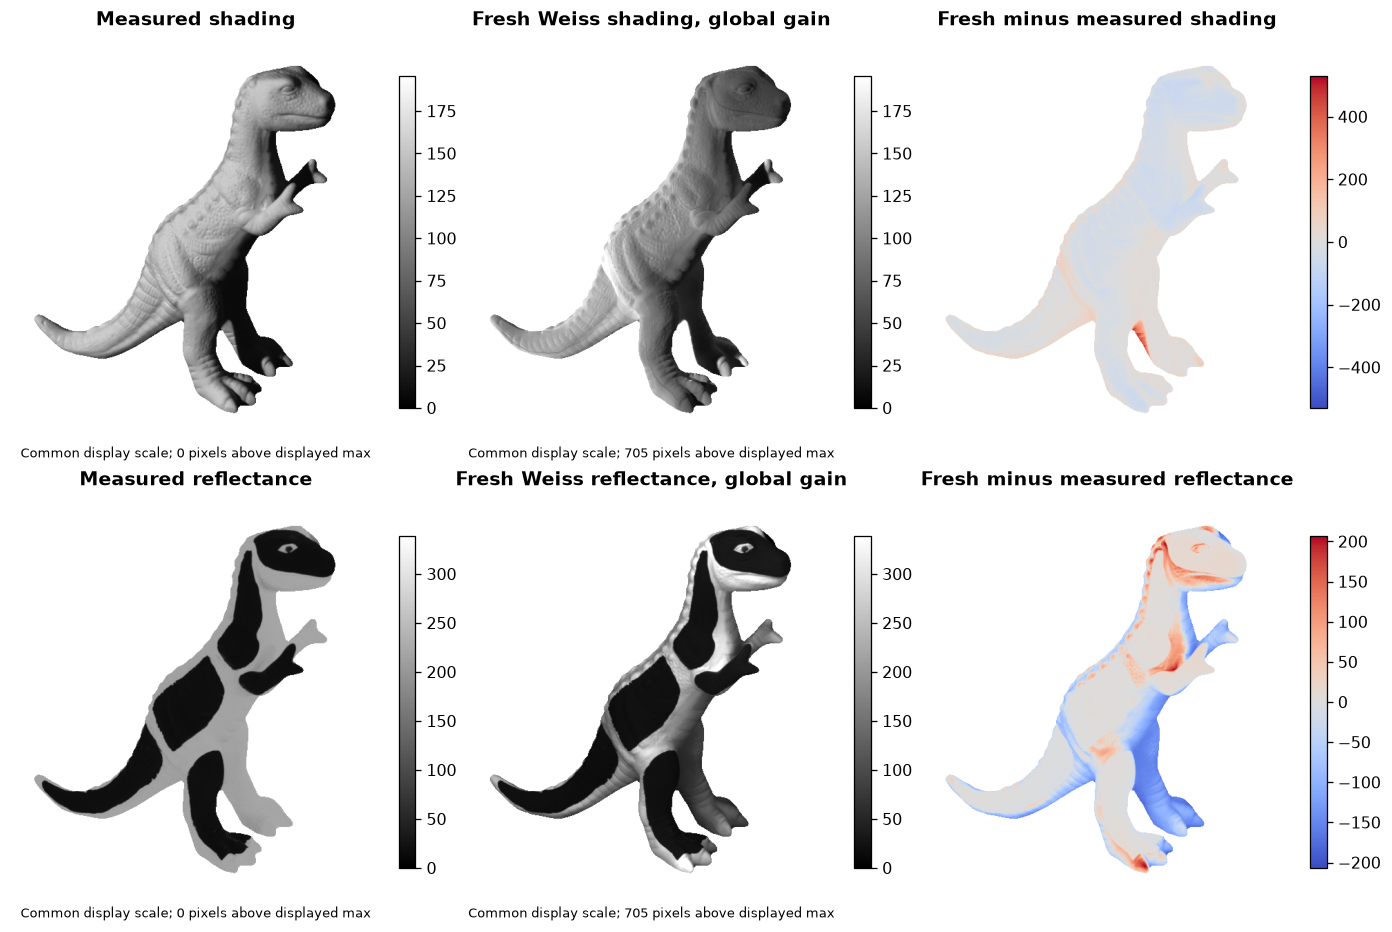

Every method / every required field, full numeric precision
{
  "Weiss": {
    "shading": {
      "ncc": 0.9270696036328452,
      "nrmse": 0.24241877657107289,
      "source_lmse": 0.01929096515736574,
      "positive_scale": 3.488072603858212
    },
    "reflectance": {
      "ncc": 0.908013083494079,
      "nrmse": 0.2776307687866266,
      "source_lmse": 0.03638409060143498,
      "positive_scale": 60.21636409930645
    }
  },
  "Gray Retinex": {
    "shading": {
      "ncc": 0.958507426395846,
      "nrmse": 0.18433638462305463,
      "source_lmse": 0.021573651594505947,
      "positive_scale": 4.200003530907784
    },
    "reflectance": {
      "ncc": 0.8352653967771474,
      "nrmse": 0.3643810191139252,
      "source_lmse": 0.0984439165246832,
      "positive_scale": 46.623324803909945
    }
  },
  "Color Retinex (RGB context)": {
    "shading": {
      "ncc": 0.9585052398246575,
      "nrmse": 0.1843411387248586,
      "source_lmse": 0.021315222942079985,
      "positive_scale

In [5]:
quality={}
for name,out in fresh_methods.items():quality[name]={key:field_metrics(out[key],truth[key],m) for key in ('shading','reflectance')}
fig,axes=plt.subplots(2,3,figsize=(12,8),constrained_layout=True)
for row,key in enumerate(('shading','reflectance')):
    scale=quality['Weiss'][key]['positive_scale'];prediction=fresh[key]*scale;error=prediction-truth[key]
    vmax=float(np.percentile(np.concatenate([truth[key][m],prediction[m]]),99.5));extent=float(np.max(abs(error[m])))
    for col,array,title in [(0,truth[key],f'Measured {key}'),(1,prediction,f'Fresh Weiss {key}, global gain'),(2,error,f'Fresh minus measured {key}')]:
        ax=axes[row,col];im=ax.imshow(np.where(m,array,np.nan),cmap='coolwarm' if col==2 else 'gray',vmin=-extent if col==2 else 0,vmax=extent if col==2 else vmax);ax.set_title(title);ax.axis('off');fig.colorbar(im,ax=ax,shrink=.8)
        if col<2:ax.text(.5,-.02,f'Common display scale; {int(np.sum(array[m]>vmax))} pixels above displayed max',transform=ax.transAxes,ha='center',fontsize=8)
plt.show()
print('Every method / every required field, full numeric precision');print(json.dumps(quality,indent=2))

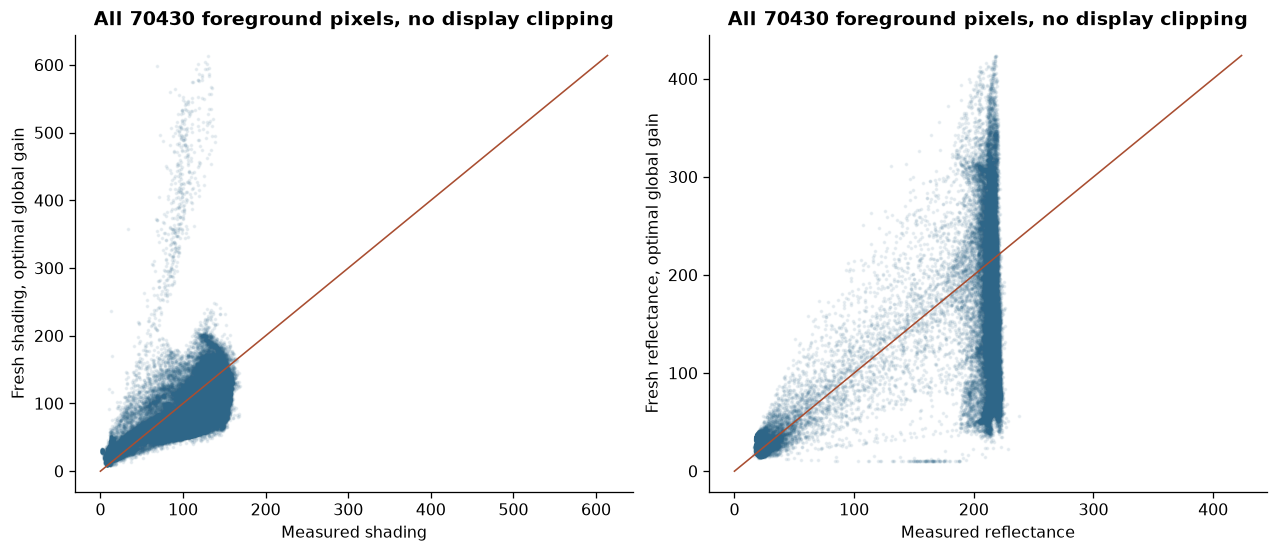

Localized large errors remain; complete scatter and Judge use every foreground value. Common map display scaling does not alter evaluated arrays.


In [6]:
fig,axes=plt.subplots(1,2,figsize=(11,4.7),constrained_layout=True)
for ax,key in zip(axes,('shading','reflectance')):
    measured=truth[key][m];predicted=fresh[key][m]*quality['Weiss'][key]['positive_scale'];extent=max(float(measured.max()),float(predicted.max()))
    ax.scatter(measured,predicted,s=2,alpha=.08,rasterized=True,color='#2e6688');ax.plot([0,extent],[0,extent],color='#a94e31',linewidth=1);ax.set_xlabel(f'Measured {key}');ax.set_ylabel(f'Fresh {key}, optimal global gain');ax.set_title(f'All {int(m.sum())} foreground pixels, no display clipping')
plt.show()
print('Localized large errors remain; complete scatter and Judge use every foreground value. Common map display scaling does not alter evaluated arrays.')

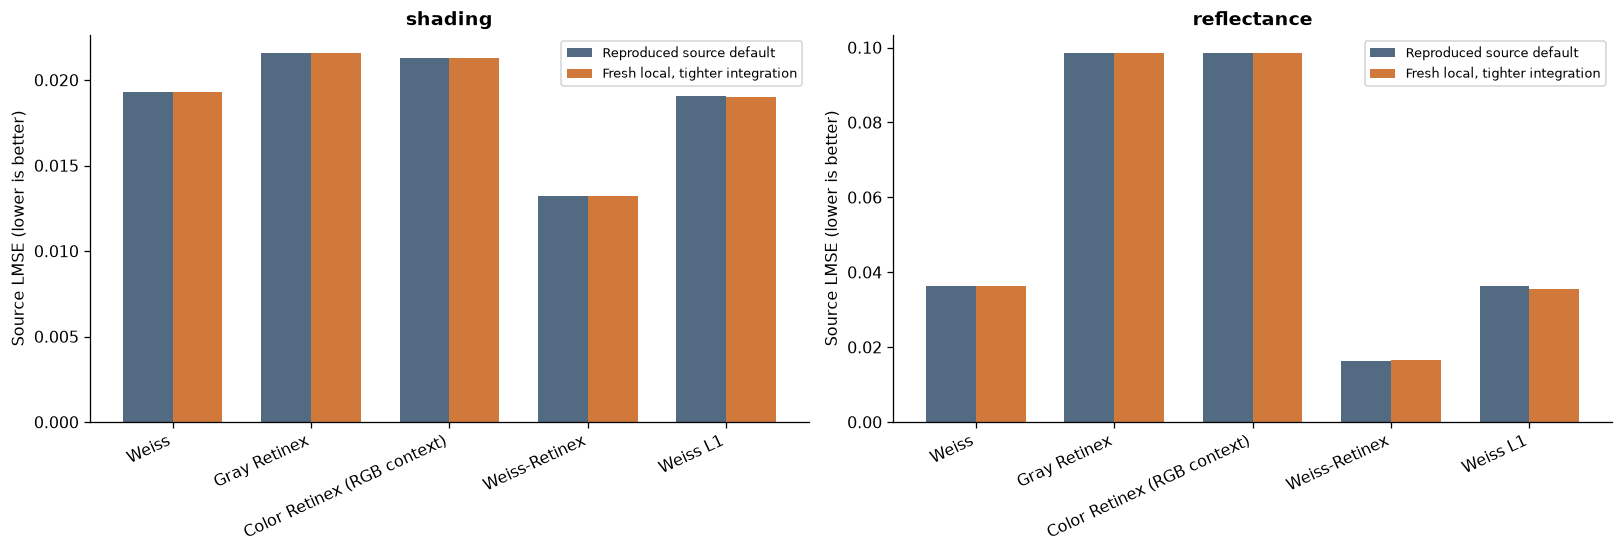

Original and local algorithms have explicit numerical integration differences; color uses additional RGB input. No whole-paper leaderboard claim.


In [7]:
# Preserved source-default comparisons and fresh measurements have separate bars.
with np.load(REF/'upstream_controls.npz',allow_pickle=False) as z:archived_controls={k:z[k] for k in z.files}
source_names={'Gray Retinex':'gray_retinex_fixed01','Color Retinex (RGB context)':'color_retinex_fixed01','Weiss-Retinex':'weiss_retinex_fixed01','Weiss L1':'weiss_L1'}
source_methods={'Weiss':upstream}
for name,prefix in source_names.items():source_methods[name]={key:archived_controls[prefix+'_'+key] for key in ('shading','reflectance')}
source_quality={name:{key:field_metrics(out[key],truth[key],m) for key in ('shading','reflectance')} for name,out in source_methods.items()}
labels=list(fresh_methods);positions=np.arange(len(labels));fig,axes=plt.subplots(1,2,figsize=(14,4.7),constrained_layout=True)
for ax,key in zip(axes,('shading','reflectance')):
    ax.bar(positions-.18,[source_quality[n][key]['source_lmse'] for n in labels],.36,label='Reproduced source default',color='#526b83')
    ax.bar(positions+.18,[quality[n][key]['source_lmse'] for n in labels],.36,label='Fresh local, tighter integration',color='#d1793b')
    ax.set_xticks(positions,labels,rotation=25,ha='right');ax.set_ylabel('Source LMSE (lower is better)');ax.set_title(key);ax.legend(fontsize=8)
plt.show()
print('Original and local algorithms have explicit numerical integration differences; color uses additional RGB input. No whole-paper leaderboard claim.')

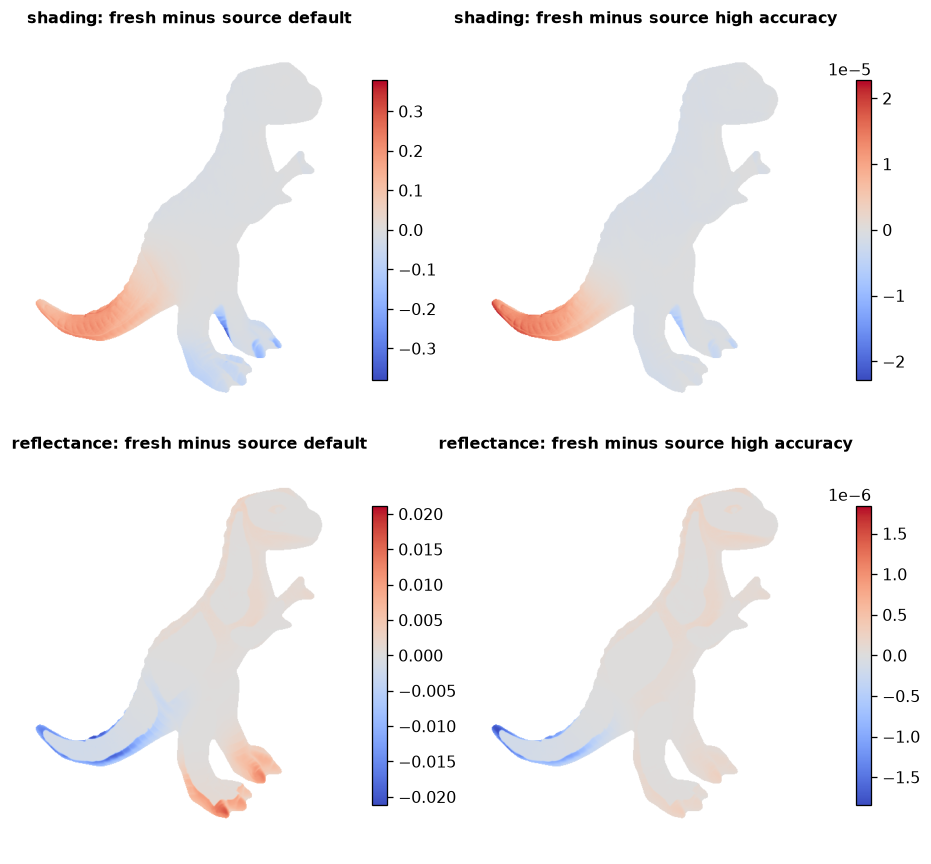

{
  "shading": {
    "source default": {
      "max_absolute": 0.37896261465266434,
      "range_nrmse": 0.0003314711052173709
    },
    "source high accuracy": {
      "max_absolute": 2.2773996597891255e-05,
      "range_nrmse": 1.9828820157139634e-08
    }
  },
  "reflectance": {
    "source default": {
      "max_absolute": 0.021182540390673132,
      "range_nrmse": 0.00045559520398600326
    },
    "source high accuracy": {
      "max_absolute": 1.845131300193259e-06,
      "range_nrmse": 2.494634638596008e-08
    }
  }
}


In [8]:
# Direct numeric comparison, with fixed support and source gauge conventions.
with np.load(ROOT/'test/fixtures/high_accuracy_primary.npz',allow_pickle=False) as z:high={k:z[k] for k in ('shading','reflectance')}
parity={};images=[];names=[]
for key in ('shading','reflectance'):
    parity[key]={}
    for label,ref in [('source default',upstream[key]),('source high accuracy',high[key])]:
        difference=fresh[key]-ref;parity[key][label]={'max_absolute':float(np.max(abs(difference[m]))),'range_nrmse':float(np.sqrt(np.mean(difference[m]**2))/np.ptp(ref[m]))}
        images.append(np.where(m,difference,np.nan));names.append(f'{key}: fresh minus {label}')
image_grid(images,names,columns=2,cmap='coolwarm');plt.show();print(json.dumps(parity,indent=2))
assert all(parity[k]['source default']['range_nrmse']<=.001 and parity[k]['source high accuracy']['range_nrmse']<=1e-7 for k in ('shading','reflectance'))

The next experiments are actual recomputations, not cached example pictures. Illumination-count sensitivity uses predeclared first-light prefixes rather than choosing the most favorable lights. A permuted complete stack tests an invariant of the physical acquisition model.

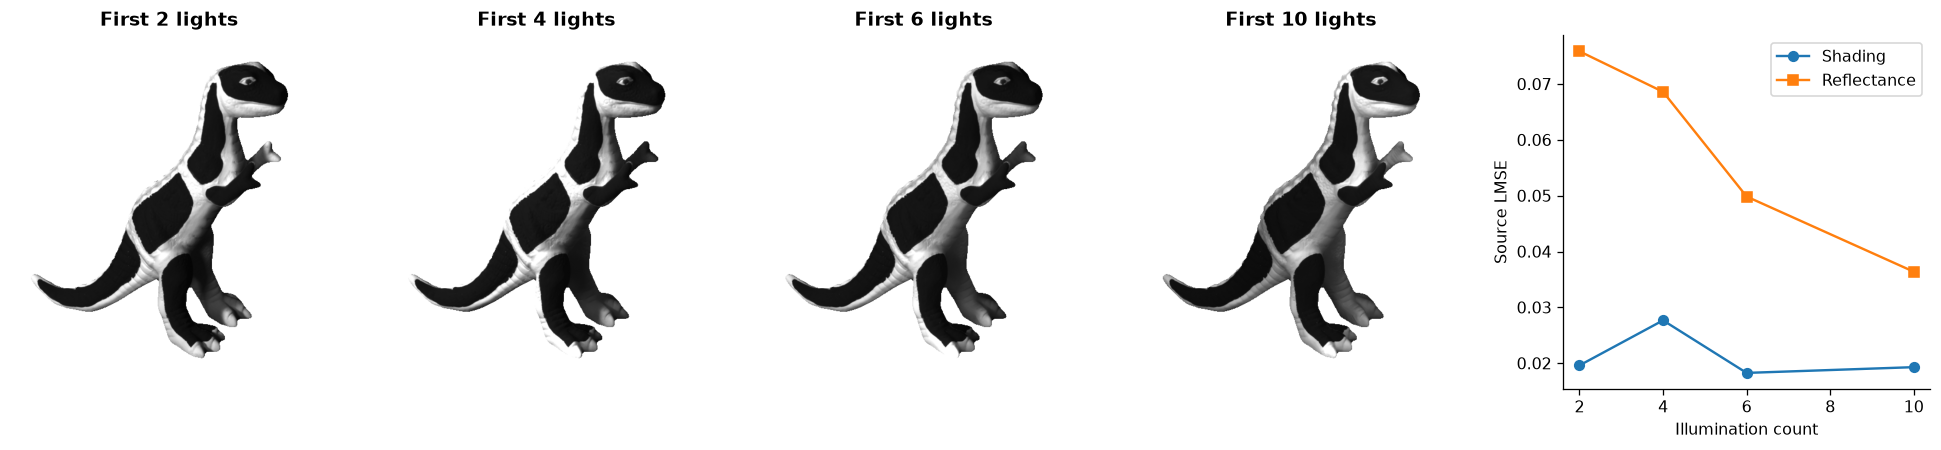

All10 illumination permutation: bitwise invariant
Prefix full-field LMSE [[0.019609847236097606, 0.07585303732794271], [0.027670635697345854, 0.0686002399822962], [0.01826224288942402, 0.04984407298118054], [0.01929096515736574, 0.03638409060143498]]


In [9]:
counts=[2,4,6,10];subset_results=[];subset_errors=[]
for count in counts:
    result=fresh if count==10 else estimate(x['image'],x['multiple'][...,:count],m)
    subset_results.append(result);subset_errors.append([field_metrics(result[k],truth[k],m)['source_lmse'] for k in ('shading','reflectance')])
permuted=estimate(x['image'],x['multiple'][...,[9,0,8,1,7,2,6,3,5,4]],m)
assert all(np.array_equal(permuted[k],fresh[k]) for k in ('shading','reflectance'))
fig,axes=plt.subplots(1,5,figsize=(17,3.8),constrained_layout=True)
for ax,count,result in zip(axes[:4],counts,subset_results):
    im=ax.imshow(np.where(m,result['reflectance'],np.nan),cmap='gray',vmin=0,vmax=np.percentile(fresh['reflectance'][m],99));ax.set_title(f'First {count} lights');ax.axis('off')
axes[4].plot(counts,np.array(subset_errors)[:,0],'o-',label='Shading');axes[4].plot(counts,np.array(subset_errors)[:,1],'s-',label='Reflectance');axes[4].set_xlabel('Illumination count');axes[4].set_ylabel('Source LMSE');axes[4].legend();plt.show()
print('All10 illumination permutation: bitwise invariant');print('Prefix full-field LMSE',subset_errors)

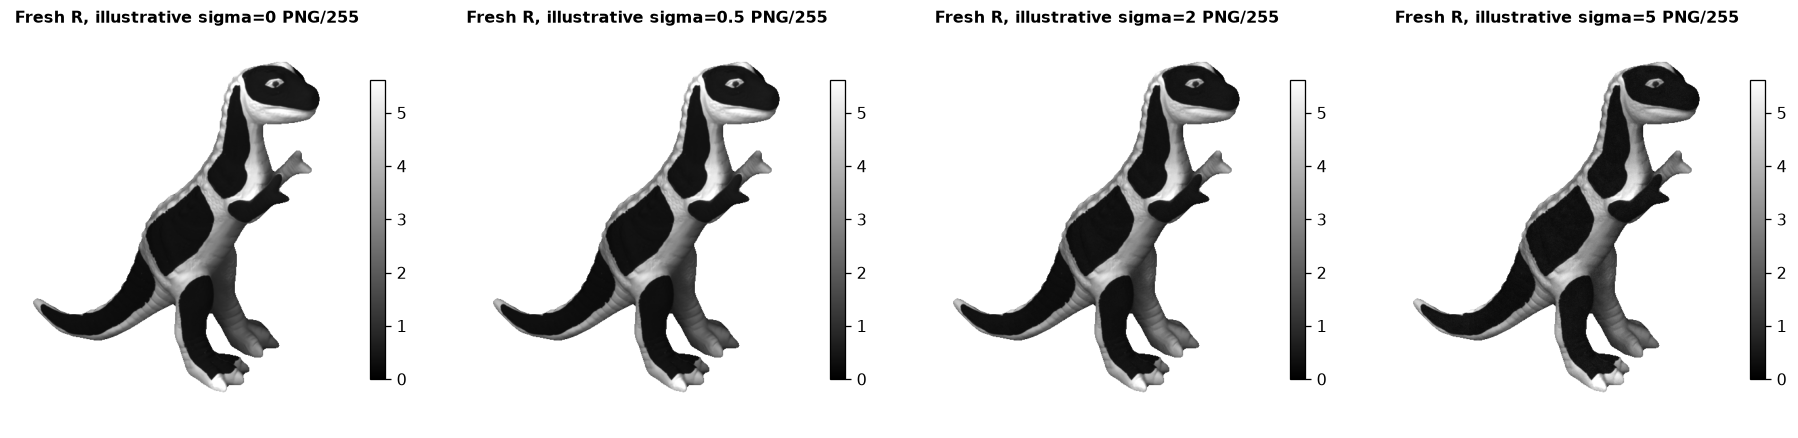

Synthetic stress only, not calibrated sensor noise: [(0.0, [0.01929096515736574, 0.03638409060143498]), (0.5, [0.021662673148379347, 0.03839771072038243]), (2.0, [0.04317574074499936, 0.04040464759818337]), (5.0, [0.13389516147744787, 0.0405268840887436])]


In [10]:
sigmas=[0.,.5,2.,5.];noise_results=[];noise_quality=[]
for sigma in sigmas:
    noisy_image,noisy_multiple=perturb_observations(x['image'],x['multiple'],sigma)
    result=fresh if sigma==0 else estimate(noisy_image,noisy_multiple,m)
    noise_results.append(result);noise_quality.append([field_metrics(result[k],truth[k],m)['source_lmse'] for k in ('shading','reflectance')])
image_grid([np.where(m,r['reflectance'],np.nan) for r in noise_results],[f'Fresh R, illustrative sigma={s:g} PNG/255' for s in sigmas],columns=4,limits=(0,float(np.percentile(fresh['reflectance'][m],99))));plt.show()
print('Synthetic stress only, not calibrated sensor noise:',list(zip(sigmas,noise_quality)))
np.savez_compressed(export/'subset_fields.npz',**{f'{key}_{count}':result[key][None] for count,result in zip(counts,subset_results) for key in ('shading','reflectance')})
np.savez_compressed(export/'noise_fields.npz',**{f'{key}_{i}':result[key][None] for i,result in enumerate(noise_results) for key in ('shading','reflectance')})

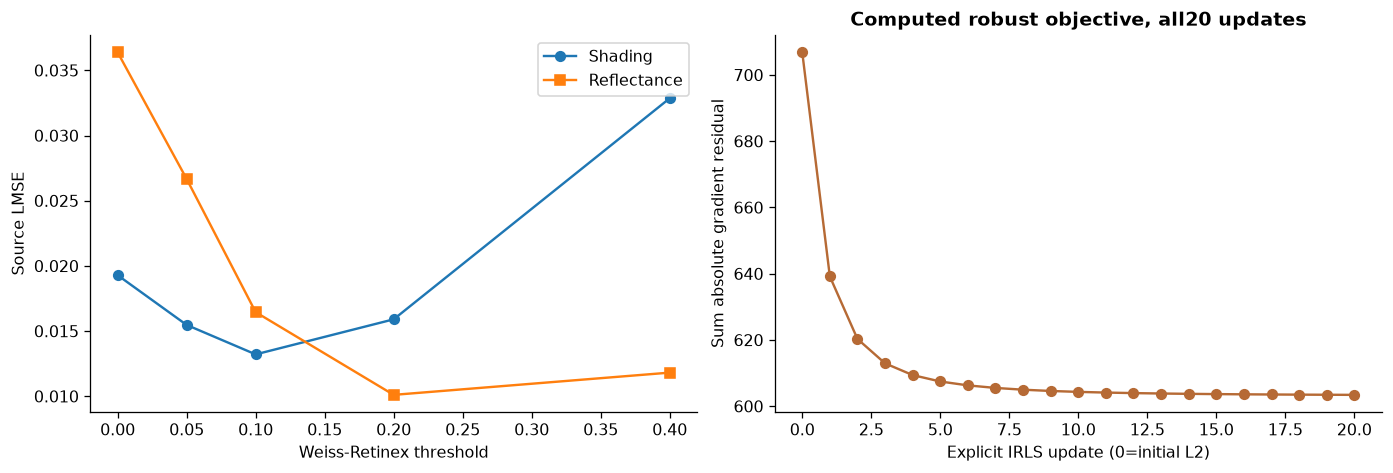

Fixed-threshold sensitivity: [(0.0, [0.01929096515736574, 0.03638409060143498]), (0.05, [0.015475299321832102, 0.026672561174966428]), (0.1, [0.01321780076392376, 0.016457623630608428]), (0.2, [0.015906631619107603, 0.010112470572301212]), (0.4, [0.03286010097074948, 0.011818641012590846])]
Actual L1 update count 20


In [11]:
thresholds=[0.,.05,.1,.2,.4];threshold_results=[];threshold_quality=[]
for threshold in thresholds:
    result=fresh if threshold==0 else estimate(x['image'],x['multiple'],m,method='weiss_retinex',threshold=threshold)
    threshold_results.append(result);threshold_quality.append([field_metrics(result[k],truth[k],m)['source_lmse'] for k in ('shading','reflectance')])
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
axes[0].plot(thresholds,np.array(threshold_quality)[:,0],'o-',label='Shading');axes[0].plot(thresholds,np.array(threshold_quality)[:,1],'s-',label='Reflectance');axes[0].set_xlabel('Weiss-Retinex threshold');axes[0].set_ylabel('Source LMSE');axes[0].legend()
trace=fresh_methods['Weiss L1']['integration'];axes[1].plot(np.arange(len(trace)),[r['gradient_l1'] for r in trace],'o-',color='#b66a35');axes[1].set_xlabel('Explicit IRLS update (0=initial L2)');axes[1].set_ylabel('Sum absolute gradient residual');axes[1].set_title('Computed robust objective, all20 updates');plt.show()
print('Fixed-threshold sensitivity:',list(zip(thresholds,threshold_quality)));print('Actual L1 update count',len(trace)-1)
assert len(trace)==21

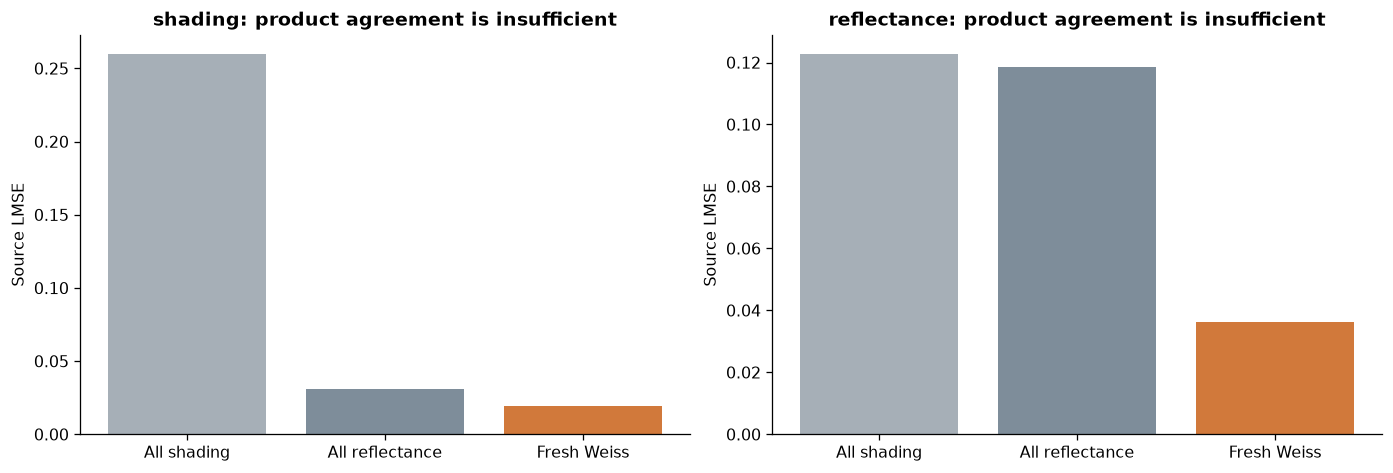

Actual active review seconds 113.41213749999588
No cached mode used.


In [12]:
nulls={'All shading':{'shading':x['image']*m,'reflectance':m.astype(float)},'All reflectance':{'shading':m.astype(float),'reflectance':x['image']*m}}
null_quality={name:{key:field_metrics(out[key],truth[key],m) for key in ('shading','reflectance')} for name,out in nulls.items()}
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for ax,key in zip(axes,('shading','reflectance')):
    names=['All shading','All reflectance','Fresh Weiss'];values=[null_quality[n][key]['source_lmse'] for n in names[:2]]+[quality['Weiss'][key]['source_lmse']]
    ax.bar(names,values,color=['#a6afb7','#7e8d9a','#d1793b']);ax.set_ylabel('Source LMSE');ax.set_title(f'{key}: product agreement is insufficient')
plt.show()
summary={'primary_seconds':primary_seconds,'method_seconds':method_seconds,'fresh_quality':quality,'source_default_quality':source_quality,'source_parity':parity,'subset_counts':counts,'subset_lmse':subset_errors,'stress_sigmas':sigmas,'stress_lmse':noise_quality,'thresholds':thresholds,'threshold_lmse':threshold_quality,'null_quality':null_quality,'foreground_pixels':int(m.sum()),'native_shape':list(m.shape),'elapsed_review_seconds':time.perf_counter()-started}
(REF/'fresh_review_metrics.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf8')
np.savez_compressed(REF/'fresh_cleaned.npz',shading=fresh['shading'][None],reflectance=fresh['reflectance'][None])
np.savez_compressed(export/'threshold_fields.npz',**{f'{key}_{i}':result[key][None] for i,result in enumerate(threshold_results) for key in ('shading','reflectance')})
np.savez_compressed(export/'fresh_comparison_fields.npz',**{f'{key}_{i}':fresh_methods[name][key][None] for i,name in enumerate(fresh_methods) for key in ('shading','reflectance')})
(export/'experiment_summary.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf8')
print('Actual active review seconds',summary['elapsed_review_seconds']);print('No cached mode used.')

## 6. Conclusion

The complete ten-light inverse is actively reconstructed and both relative fields are evaluated. Independent reference errors, nontrivial null decompositions, illumination-count sensitivity, noise stress and robust-objective traces expose what image-product agreement alone cannot establish. The optional Weiss–Retinex comparison may improve this object, but it is not substituted for the preselected parameter-free benchmark.

Limitations remain: unknown photometric calibration, illumination changes that do not have zero-median gradients, shadows and non-diffuse effects, and the independent relative gains of measured reference fields. RGB comparison uses additional input, and illustrative Gaussian noise is not an instrument characterization. Original-default, separately tighter source, and fresh local numerical results have distinct provenance. This task does not reproduce the paper's complete trained-method evaluation or establish absolute material reflectance.